In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [12]:
data = {
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "exam_score": [35, 40, 50, 55, 60, 65, 70, 78, 85, 88]
}

df = pd.DataFrame(data)
df

,study_hours,exam_score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,60
5,6,65
6,7,70
7,8,78
8,9,85
9,10,88


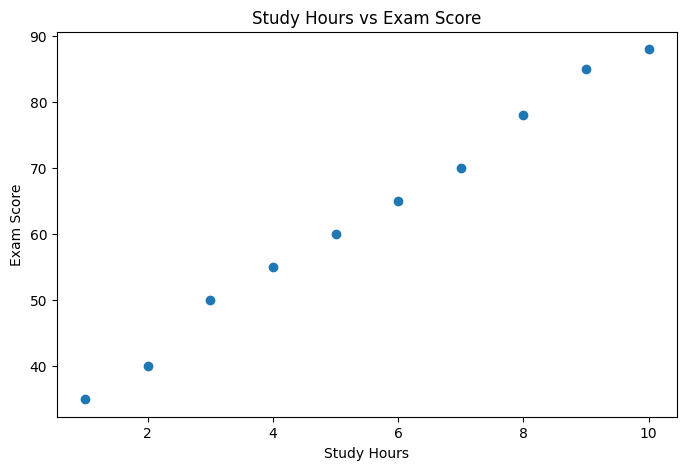

In [13]:
#scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df["study_hours"], df["exam_score"])

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.savefig("figures/scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
X = df[["study_hours"]]
y = df["exam_score"]

model = LinearRegression()
model.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
coefficient = model.coef_[0]
intercept = model.intercept_

print("Coefficient:", coefficient)
print("Intercept:", intercept)

Coefficient: 5.951515151515151
Intercept: 29.866666666666667


In [16]:
#tahminleri al

y_pred = model.predict(X)

df["predicted_score"] = y_pred
df["residual"] = df["exam_score"] - df["predicted_score"]

df

,study_hours,exam_score,predicted_score,residual
0,1,35,35.818182,-0.818182
1,2,40,41.769697,-1.769697
2,3,50,47.721212,2.278788
3,4,55,53.672727,1.327273
4,5,60,59.624242,0.375758
5,6,65,65.575758,-0.575758
6,7,70,71.527273,-1.527273
7,8,78,77.478788,0.521212
8,9,85,83.430303,1.569697
9,10,88,89.381818,-1.381818


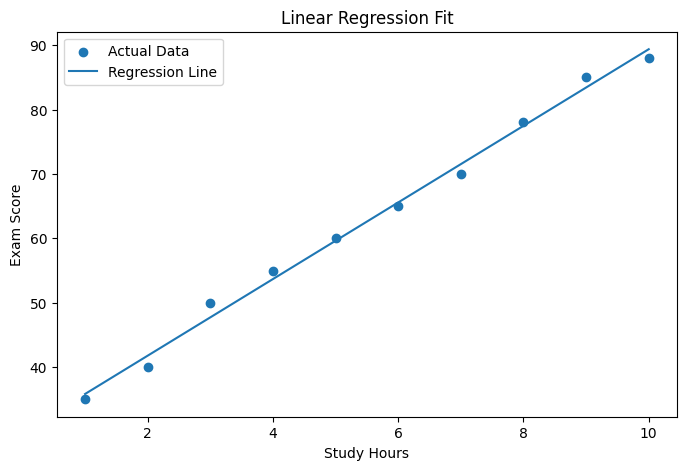

In [17]:
#regresyon eğrisi

plt.figure(figsize=(8, 5))

plt.scatter(df["study_hours"], df["exam_score"], label="Actual Data")
plt.plot(df["study_hours"], df["predicted_score"], label="Regression Line")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Linear Regression Fit")
plt.legend()

plt.savefig("figures/regression_line.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
#metrikler

mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.2145454545454535
MSE: 1.820606060606058
RMSE: 1.3492983586316474
R²: 0.993808304786403


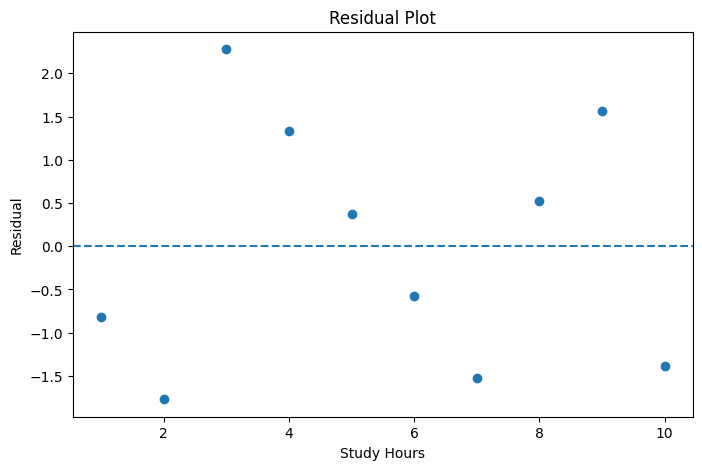

In [19]:
#residual plot

plt.figure(figsize=(8, 5))

plt.scatter(df["study_hours"], df["residual"])
plt.axhline(y=0, linestyle="--")

plt.xlabel("Study Hours")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.savefig("figures/residual_plot.png", dpi=300, bbox_inches="tight")
plt.show()

## XAI Interpretation

Linear Regression is an intrinsically interpretable model.

Unlike complex black-box models, its prediction mechanism can be directly understood from its coefficient and intercept.

In this project, the model learns a relationship between study hours and exam scores.

The coefficient explains how much the predicted exam score changes when study hours increase by one unit.

The intercept represents the baseline prediction when study hours are zero.

For a single prediction, the model decision can be explained by substituting the input value into the learned equation.

Residual analysis gives another layer of explanation by showing where the model makes errors.

This means that explainability is not only about understanding why a prediction was made, but also about understanding when and where the model may be wrong.